# 02: baseline vs contrastive, multi-seed

In [1]:
import math
import numpy as np, torch, torch.nn.functional as F
from torch import nn
from sklearn.metrics import roc_auc_score

In [2]:
class MLP(nn.Module):
    def __init__(self, i, h, o):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(i, h), nn.ReLU(), nn.Linear(h, o))
    def forward(self, x): return self.net(x)

class Multi(nn.Module):  # one MLP per view; stack_dim=1 -> (N, K, o), 0 -> (K, N, o)
    def __init__(self, K, i, h, o, stack_dim):
        super().__init__()
        self.nets = nn.ModuleList([MLP(i, h, o) for _ in range(K)]); self.sd = stack_dim
    def forward(self, x):
        pick = (lambda k: x[k]) if self.sd == 1 else (lambda k: x[:, k])
        return torch.stack([self.nets[k](pick(k)) for k in range(len(self.nets))], dim=self.sd)

class GraphLearner(nn.Module):
    def __init__(self, d, thr):
        super().__init__()
        self.lens = nn.Sequential(nn.Linear(d, d), nn.LeakyReLU()); self.thr = thr
    def forward(self, H):
        h = F.normalize(self.lens(H), dim=2)
        A = (h @ h.transpose(1, 2)).abs()
        return torch.where(A < self.thr, torch.zeros_like(A), A), h

class LegatoMini(nn.Module):
    def __init__(self, K, d_in, hid, emb, thr):
        super().__init__()
        self.enc = Multi(K, d_in, hid, emb, 1); self.gl = GraphLearner(emb, thr); self.dec = Multi(K, emb, hid, d_in, 0)
    def forward(self, views):
        H = self.enc(views); A, h = self.gl(H)
        return self.dec(F.normalize(A, p=1, dim=-1) @ H), A, h

def info_nce(a, b, tau=0.1):
    a, b = F.normalize(a, dim=1), F.normalize(b, dim=1)
    return F.cross_entropy(a @ b.T / tau, torch.arange(a.shape[0]))

def pair_losses(h):  # list of info_nce over pairs i<j, same order as np.triu_indices(K, 1)
    K = h.shape[1]
    return [info_nce(h[:, i], h[:, j]) for i in range(K) for j in range(i + 1, K)]

In [3]:
def evaluate(model, views, true):
    K = views.shape[0]
    with torch.no_grad():
        recon, A, h = model(views)
        L = np.array([l.item() for l in pair_losses(h)])
    iu = np.triu_indices(K, 1); t = true[iu]
    mse = F.mse_loss(recon, views).item()
    var = ((views - views.mean(1, keepdim=True)) ** 2).mean().item()
    return dict(auc_A=roc_auc_score(t, A.mean(0).numpy()[iu]),
                auc_infonce=roc_auc_score(t, math.log(views.shape[1]) - L),
                recon=mse, r2=1 - mse / var,
                loss_true=L[t == 1].mean(), loss_false=L[t == 0].mean())

In [4]:
def run(seed, lam, w=0.5, K=6, epochs=200, thr=0.1):
    d = np.load(f"../derived/sim_local_K{K}_w{w}_seed{seed}.npz")
    views, lab, true = torch.tensor(d["views_unlab"]), torch.tensor(d["views_lab"]), d["true_edges"]
    torch.manual_seed(seed)
    model = LegatoMini(K, 100, 64, 16, thr)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    for ep in range(epochs):
        opt.zero_grad()
        recon, A, h = model(views)
        lc = torch.stack(pair_losses(h)).mean()
        loss = F.mse_loss(recon, views) + lam * lc
        loss.backward(); opt.step()
    tr, te = evaluate(model, views, true), evaluate(model, lab, true)
    return dict(seed=seed, lam=lam, w=w, **tr, **{"te_" + k: v for k, v in te.items()})

In [5]:
for lam in (0, 1):
    print(run(0, lam))

{'seed': 0, 'lam': 0, 'w': 0.5, 'auc_A': np.float64(0.8333333333333334), 'auc_infonce': np.float64(0.4444444444444444), 'recon': 0.0010584990959614515, 'r2': 0.9827133410136244, 'loss_true': np.float64(6.73353910446167), 'loss_false': np.float64(6.736537138621013), 'te_auc_A': np.float64(0.7777777777777778), 'te_auc_infonce': np.float64(0.5277777777777778), 'te_recon': 0.001145217102020979, 'te_r2': 0.9828502102770136, 'te_loss_true': np.float64(5.342826207478841), 'te_loss_false': np.float64(5.380112250645955)}


{'seed': 0, 'lam': 1, 'w': 0.5, 'auc_A': np.float64(1.0), 'auc_infonce': np.float64(0.8055555555555556), 'recon': 0.0026808991096913815, 'r2': 0.9562174508576051, 'loss_true': np.float64(6.584611097971599), 'loss_false': np.float64(6.682935357093811), 'te_auc_A': np.float64(1.0), 'te_auc_infonce': np.float64(0.9444444444444444), 'te_recon': 0.0031811839435249567, 'te_r2': 0.9523613159414779, 'te_loss_true': np.float64(5.197245438893636), 'te_loss_false': np.float64(5.302475452423096)}


In [6]:
import pandas as pd

def sweep(seeds=range(5), lams=(0, 1), ws=(0.25, 0.5, 0.75)):
    return pd.DataFrame([run(s, l, w) for w in ws for l in lams for s in seeds])

In [7]:
import time; t0 = time.time()
df = sweep()
df.to_csv("../derived/sweep_nb02.csv", index=False)
print(f"{len(df)} runs in {time.time()-t0:.0f}s")

for split, pre in [("TRAIN", ""), ("HELD-OUT (200 samples)", "te_")]:
    cols = [pre + c for c in ["auc_A", "auc_infonce", "recon", "r2", "loss_true", "loss_false"]]
    print(split); display(df.groupby(["w", "lam"])[cols].agg(["mean", "std"]).round(3))

# paired by seed: lam=1 minus lam=0 on the same dataset and model seed
for pre in ["", "te_"]:
    piv = df.pivot_table(index=["w", "seed"], columns="lam", values=[pre + "auc_A", pre + "auc_infonce"])
    for m in [pre + "auc_A", pre + "auc_infonce"]:
        d = (piv[(m, 1)] - piv[(m, 0)]).groupby("w")
        print(m, "| mean paired diff (lam1 - lam0):", d.mean().round(3).to_dict(), "| seeds where lam1 > lam0:", d.apply(lambda x: (x > 0).sum()).to_dict(), "of 5")

30 runs in 90s
TRAIN


auc_A        auc_infonce         recon            r2         \
           mean    std        mean    std   mean    std   mean    std   
w    lam                                                                
0.25 0    0.769  0.077       0.406  0.082  0.001  0.000  0.981  0.002   
     1    0.828  0.057       0.783  0.023  0.003  0.001  0.956  0.009   
0.50 0    0.797  0.050       0.433  0.042  0.001  0.000  0.983  0.001   
     1    0.922  0.072       0.789  0.042  0.003  0.000  0.957  0.005   
0.75 0    0.814  0.107       0.517  0.144  0.001  0.000  0.982  0.002   
     1    0.989  0.015       0.800  0.036  0.003  0.000  0.953  0.006   

         loss_true        loss_false         
              mean    std       mean    std  
w    lam                                     
0.25 0       6.768  0.058      6.812  0.051  
     1       6.660  0.003      6.682  0.000  
0.50 0       6.787  0.080      6.824  0.063  
     1       6.587  0.011      6.682  0.001  
0.75 0       7.026  0.354      6.828  0.037  
     1       6.413  0.014      6.681  0.000

HELD-OUT (200 samples)


te_auc_A        te_auc_infonce        te_recon       te_r2         \
             mean    std           mean    std     mean  std   mean    std   
w    lam                                                                     
0.25 0      0.717  0.059          0.472  0.052    0.001  0.0  0.980  0.004   
     1      0.833  0.056          0.883  0.023    0.003  0.0  0.958  0.007   
0.50 0      0.794  0.064          0.494  0.072    0.001  0.0  0.982  0.001   
     1      0.922  0.072          0.867  0.066    0.003  0.0  0.958  0.004   
0.75 0      0.825  0.116          0.511  0.116    0.001  0.0  0.982  0.002   
     1      0.989  0.015          0.889  0.028    0.003  0.0  0.956  0.007   

         te_loss_true        te_loss_false         
                 mean    std          mean    std  
w    lam                                           
0.25 0          5.388  0.071         5.392  0.057  
     1          5.279  0.004         5.300  0.001  
0.50 0          5.385  0.069         5.398  0.062  
     1          5.206  0.012         5.300  0.002  
0.75 0          5.622  0.348         5.422  0.057  
     1          5.029  0.020         5.300  0.001

auc_A | mean paired diff (lam1 - lam0): {0.25: 0.058, 0.5: 0.125, 0.75: 0.175} | seeds where lam1 > lam0: {0.25: 3, 0.5: 4, 0.75: 5} of 5
auc_infonce | mean paired diff (lam1 - lam0): {0.25: 0.378, 0.5: 0.356, 0.75: 0.283} | seeds where lam1 > lam0: {0.25: 5, 0.5: 5, 0.75: 5} of 5
te_auc_A | mean paired diff (lam1 - lam0): {0.25: 0.117, 0.5: 0.128, 0.75: 0.164} | seeds where lam1 > lam0: {0.25: 4, 0.5: 5, 0.75: 5} of 5
te_auc_infonce | mean paired diff (lam1 - lam0): {0.25: 0.411, 0.5: 0.372, 0.75: 0.378} | seeds where lam1 > lam0: {0.25: 5, 0.5: 5, 0.75: 5} of 5


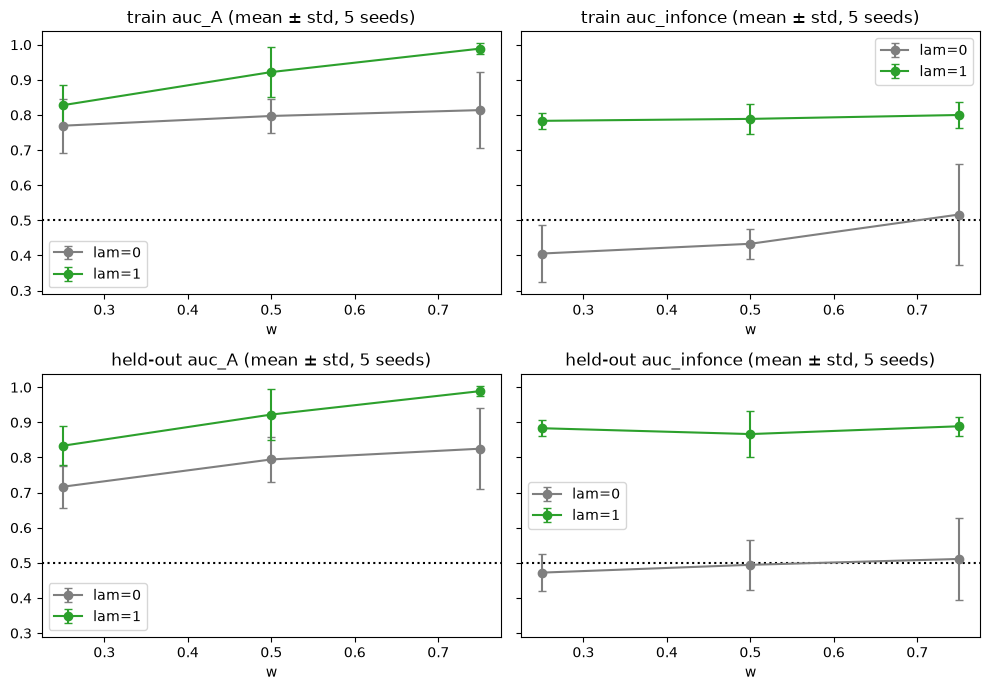

In [8]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 2, figsize=(10, 7), sharey=True)
for r, pre in enumerate(["", "te_"]):
    for a, m in zip(ax[r], ["auc_A", "auc_infonce"]):
        for lam, c in [(0, "tab:gray"), (1, "tab:green")]:
            g = df[df.lam == lam].groupby("w")[pre + m]
            a.errorbar(g.mean().index, g.mean(), yerr=g.std(), marker="o", capsize=3, color=c, label=f"lam={lam}")
        a.axhline(0.5, ls=":", color="k"); a.set_title(("held-out " if pre else "train ") + m + " (mean ± std, 5 seeds)"); a.set_xlabel("w"); a.legend()
plt.tight_layout(); plt.show()